In [ ]:
import ast
from collections import Counter
import json
import re
import time
import warnings

from bs4 import BeautifulSoup
import folium
from googlesearch import search
from kiwipiepy import Kiwi
from konlpy.tag import Okt
import matplotlib
from matplotlib import font_manager, rc
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from wordcloud import WordCloud

# 경고 메시지 무시 설정
warnings.filterwarnings(action='ignore')

# 매직 명령어 및 소수점 설정
%precision 3
%matplotlib inline

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)

In [226]:
# 그래프 선의 종류
linestyles = ['-', '--', ':']

def E(X, g=lambda x: x):
    x_set, f = X
    return np.sum([g(x_k) * f(x_k) for x_k in x_set])

def V(X, g=lambda x: x):
    x_set, f = X
    mean = E(X, g)
    return np.sum([(g(x_k)-mean)**2 * f(x_k) for x_k in x_set])

def check_prob(X):
    x_set, f = X
    prob = np.array([f(x_k) for x_k in x_set])
    assert np.all(prob >= 0), 'minus probability'
    prob_sum = np.round(np.sum(prob), 6)
    assert prob_sum == 1, f'sum of probability{prob_sum}'
    print(f'expected value {E(X):.4}')
    print(f'variance {(V(X)):.4}')

def plot_prob(X):
    x_set, f = X
    prob = np.array([f(x_k) for x_k in x_set])
    
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111)
    ax.bar(x_set, prob, label='prob')
    ax.vlines(E(X), 0, 1, label='mean')
    ax.set_xticks(np.append(x_set, E(X)))
    ax.set_ylim(0, prob.max()*1.2)
    ax.legend()
    
    plt.show()

In [227]:
df = pd.read_csv('./data/quality_inspection.csv')

In [228]:
df.head()

,date,product_id,line,shift,inspector,inspected,defect,machine temp,dow
0,2025-10-28,P127143,C,day,kim,Y,0,89.0,1
1,2025-12-06 00:00:00,P167273,A,day,han,1,0,84.37,5
2,2025-11-23,P153356,A,day,park,Y,0,86.1,6
3,2025-11-15,P145037,A,day,seo,N,NaN,83.46,5
4,2025-10-21,P121440,B,day,jung,Y,0,77.0,1


In [229]:
df['defect'].value_counts()

defect
0     66356
정상    13319
X      7123
1       193
불량       66
O        16
Name: count, dtype: int64

In [230]:
df['inspected'].value_counts()

inspected
1        35672
Y        31111
yes       9072
True      9015
T         4314
0         1542
N         1431
no         411
False      399
F          127
Name: count, dtype: int64

In [231]:
df['dow'].value_counts()

dow
2      13585
3      13086
1      12998
4      12924
6      12914
0      12880
5      12171
Fri      353
Sat      352
Wed      351
Thu      343
Tue      342
Mon      341
Sun      340
7        208
Name: count, dtype: int64

1. date 통일
2. inspected 결과 통일
3. defect 통일 (검사 안한 컬럼은 drop해도 될듯?)
4. 요일 통일(근데 문제보니깐 이건 필요없을듯)

1. 제품 1개 단위- 불량 여부 분포?

In [232]:
df['inspected']

0           Y
1           1
2           Y
3           N
4           Y
         ... 
93183    True
93184    True
93185    True
93186       Y
93187       1
Name: inspected, Length: 93188, dtype: object

In [233]:
def clean_inspected(val):
    # 문자열 변환, 양끝 공백 제거, 소문자 변환
    s = str(val).strip().lower()
    
    # 'Y'에 해당하는 값들
    if s in ['1', 'y', 'yes', 'true', 't']:
        return 1
    # 'N'에 해당하는 값들
    elif s in ['0', 'n', 'no', 'false', 'f']:
        return 0
    else:
        return None

# 적용하기
df['clean_inspected'] = df['inspected'].apply(clean_inspected)

In [234]:
df['clean_inspected'].value_counts()

clean_inspected
1.0    89184
0.0     3910
Name: count, dtype: int64

In [235]:
df['defect'].value_counts()

defect
0     66356
정상    13319
X      7123
1       193
불량       66
O        16
Name: count, dtype: int64

In [236]:
def clean_defect(val):
    # 문자열 변환, 양끝 공백 제거, 소문자 변환
    s = str(val).strip().lower()
    
    if s in ['정상', 'o', '0']:
        return 0
    # 'N'에 해당하는 값들
    elif s in ['X', '불량', '1']:
        return 1
    else:
        return None

# 적용하기
df['clean_defect'] = df['defect'].apply(clean_defect)

In [237]:
df['clean_defect'].value_counts()

clean_defect
0.0    79691
1.0      259
Name: count, dtype: int64

In [238]:
df['clean_time']=pd.to_datetime(df['date'],format='mixed')

In [239]:
df['month'] = pd.to_datetime(df['clean_time']).dt.strftime('%Y-%m')

In [240]:
df['clean_time'] = pd.to_datetime(df['clean_time']).dt.strftime('%m-%d')

In [241]:
df.head(0)

,date,product_id,line,shift,inspector,inspected,defect,machine temp,dow,clean_inspected,clean_defect,clean_time,month


expected value 0.958
variance 0.04024


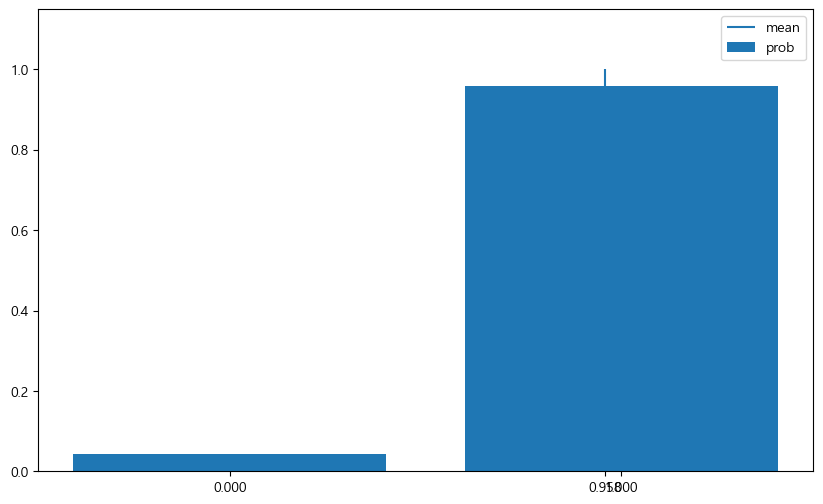

In [242]:
prob = df['clean_inspected'].value_counts(normalize=True).sort_index()

x_set = prob.index.to_numpy()

prob_dict = prob.to_dict()
f = lambda x: prob_dict.get(x, 0)

# 4. (x_set, f) 튜플 생성
X_defect = (x_set, f)

check_prob(X_defect)
plot_prob(X_defect)

In [243]:
df['clean_inspected'].value_counts()

clean_inspected
1.0    89184
0.0     3910
Name: count, dtype: int64

In [244]:
len(df['clean_time'].value_counts())

92

In [245]:
group_df = df.groupby('clean_time').count()
len(group_df)

92

In [246]:
group_df.head()

,date,product_id,line,shift,inspector,inspected,defect,machine temp,dow,clean_inspected,clean_defect,month
clean_time,,,,,,,,,,,,
10-01,1181,1175,1153,1167,1147,1181,1113,1132,1181,1181,1025,1181
10-02,984,981,963,978,961,982,931,947,984,982,853,984
10-03,833,823,813,829,811,832,801,799,833,832,744,833
10-04,969,955,946,960,933,968,901,934,969,968,831,969
10-05,1196,1185,1165,1191,1162,1194,1109,1160,1196,1194,1030,1196


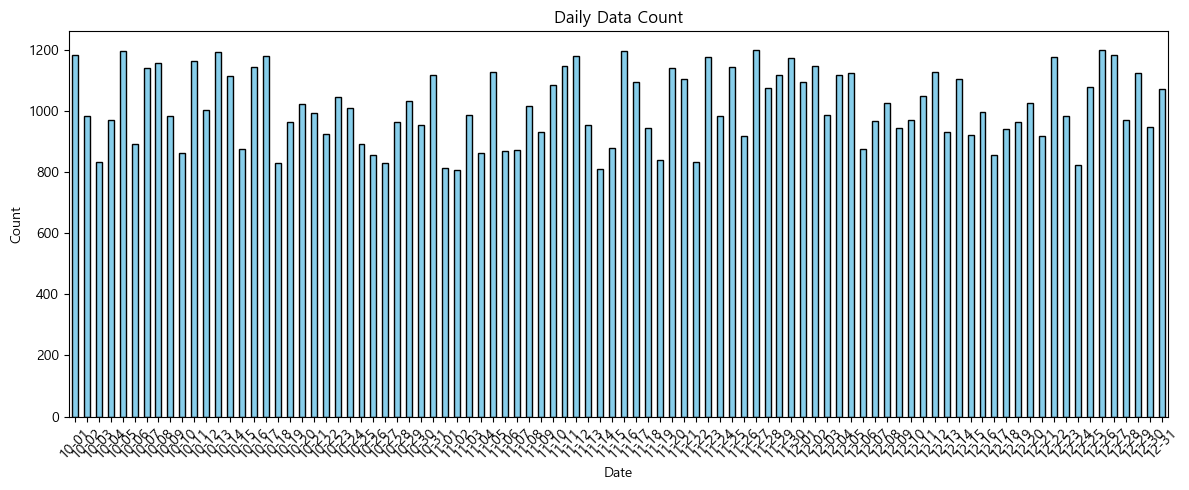

In [247]:
daily = df.groupby('clean_time').size()

fig, ax = plt.subplots(figsize=(12, 5))
daily.plot(kind='bar', ax=ax, color='skyblue', edgecolor='black')

ax.set_title('Daily Data Count')
ax.set_xlabel('Date')
ax.set_ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

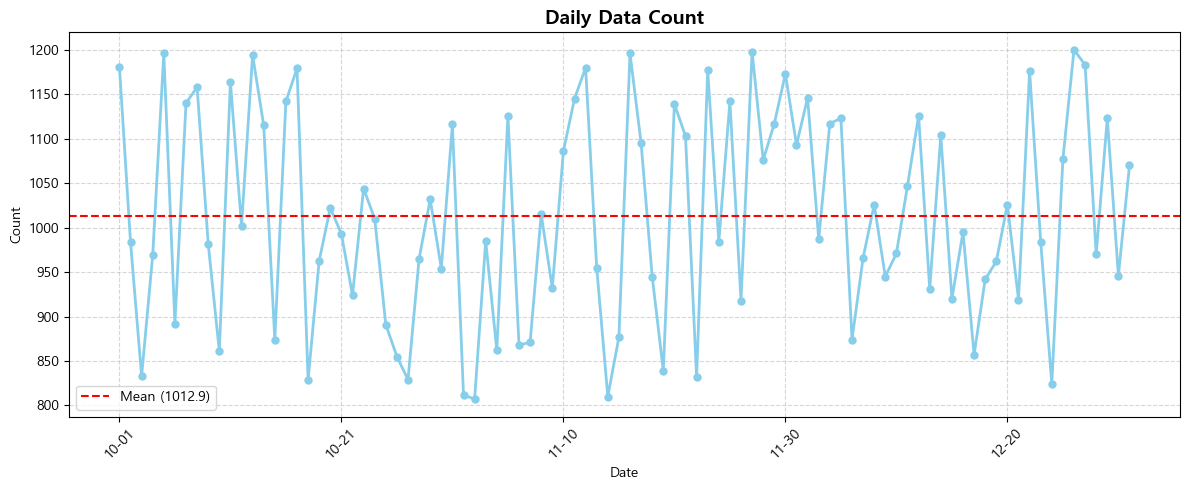

In [273]:
daily = df.groupby('clean_time').size()

fig, ax = plt.subplots(figsize=(12, 5))

daily.plot(kind='line', ax=ax, color='skyblue', marker='o', linewidth=2, markersize=5)

ax.set_title('Daily Data Count', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Count')
ax.axhline(
    y=daily.mean(),
    color='r',
    linestyle='--',
    linewidth=1.5,
    label=f'Mean ({daily.mean():.1f})',
)
plt.xticks(rotation=45)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

In [286]:
a = daily[daily >= daily.mean()]
print(f"평균보다 생산량이 높은 날 수 {len(a)} 평균보다 생산량 적은 날 수 {len(daily)-len(a)}")
print(f"평균이상인 날들의 총 생산량 {a.sum()}, 평균 이하인 날들의 총 생산량 {daily.sum()-a.sum()}")
b = daily[daily == daily.mean()]
b

평균보다 생산량이 높은 날 수 43 평균보다 생산량 적은 날 수 49
평균이상인 날들의 총 생산량 48288, 평균 이하인 날들의 총 생산량 44900


Series([], dtype: int64)

In [249]:
daily

clean_time
10-01    1181
10-02     984
10-03     833
10-04     969
10-05    1196
         ... 
12-27    1183
12-28     970
12-29    1123
12-30     946
12-31    1070
Length: 92, dtype: int64

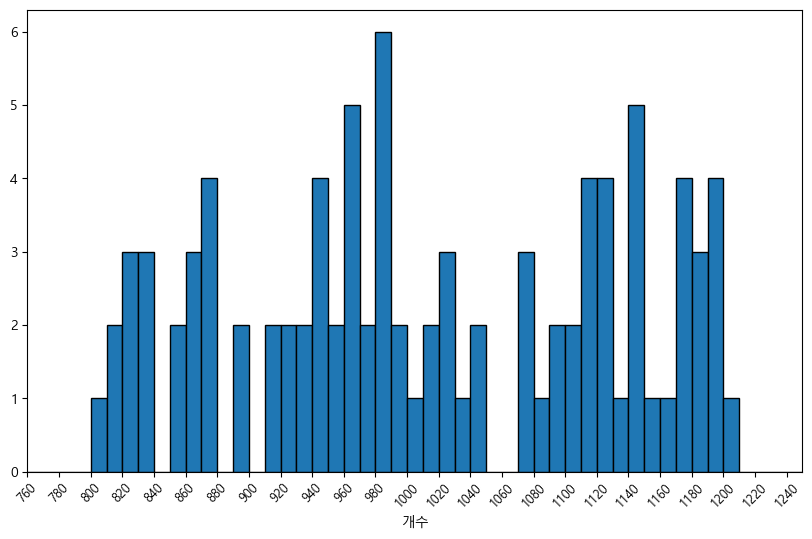

In [287]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
ax.hist(daily, bins=50, range=(750, 1250), edgecolor='black',)
ax.set_xlabel('개수')
ax.set_xlim(760, 1250)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.set_xticks(np.arange(760, 1251, 20))
plt.show()

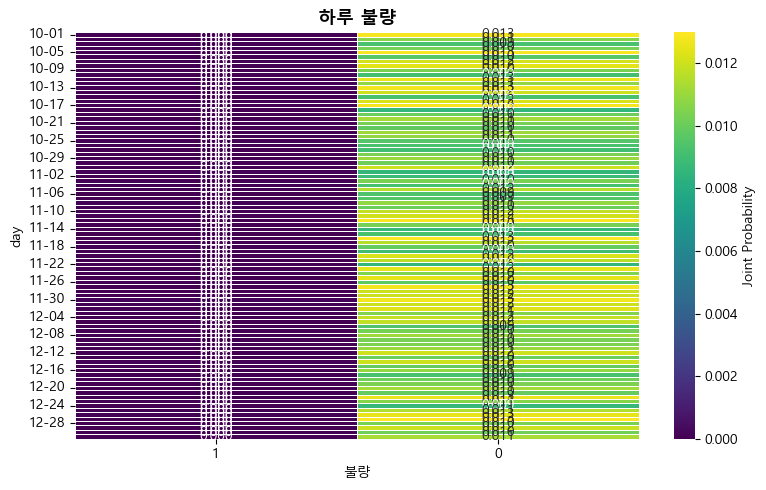

In [251]:
prob = pd.crosstab(df['clean_time'], df['clean_defect'], normalize=True)

cols = [1, 0]
prob = prob.reindex(columns=[c for c in cols if c in prob.columns])

plt.figure(figsize=(8, 5))

sns.heatmap(
    prob,
    annot=True,
    cmap='viridis',
    linewidths=0.5,
    fmt='.3f',
    cbar_kws={'label': 'Joint Probability'},
)

plt.title(
    '하루 불량',
    fontsize=13,
    fontweight='bold',
)
plt.ylabel('day')
plt.xlabel('불량')

plt.tight_layout()
plt.show()

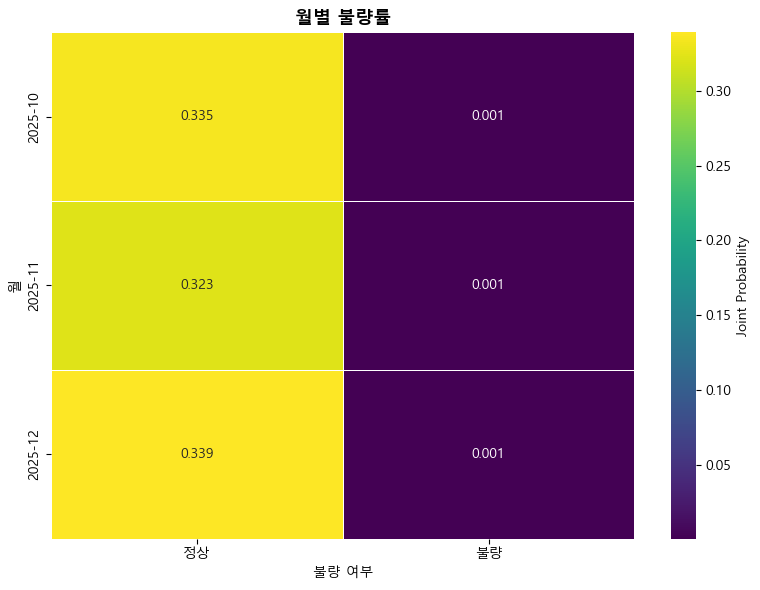

In [252]:
prob = pd.crosstab(df['month'], df['clean_defect'], normalize=True)

cols = [0, 1]
prob = prob.reindex(columns=[c for c in cols if c in prob.columns])
prob.columns = ['정상', '불량']

plt.figure(figsize=(8, 6))

sns.heatmap(
    prob,
    annot=True,
    cmap='viridis',
    linewidths=0.5,
    fmt='.3f',
    cbar_kws={'label': 'Joint Probability'}
)

plt.title('월별 불량률', fontsize=13, fontweight='bold')
plt.xlabel('불량 여부')
plt.ylabel('월')

plt.tight_layout()
plt.show()

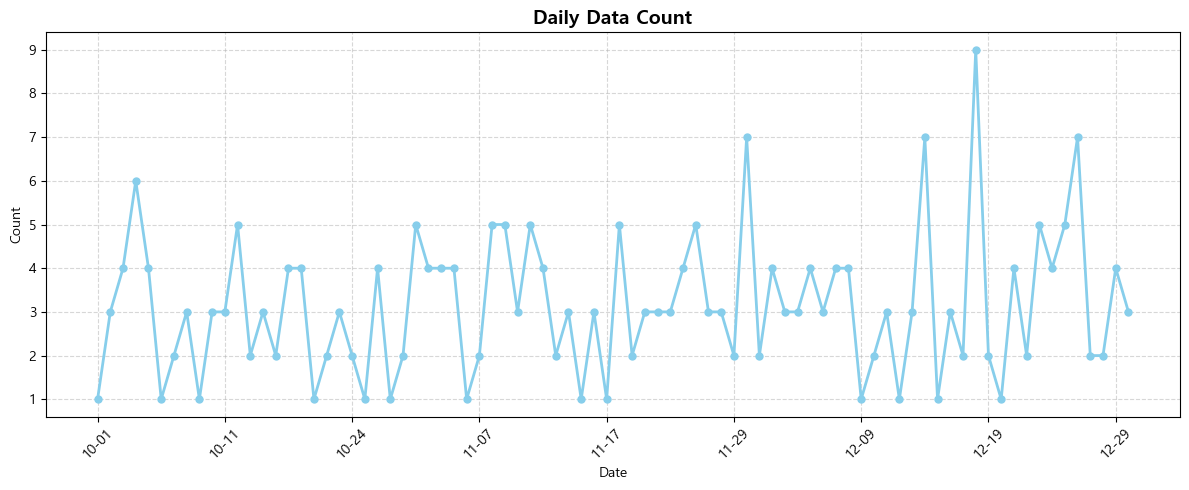

In [289]:
daily = df[df['clean_defect'] == 1].groupby('clean_time').size()

fig, ax = plt.subplots(figsize=(12, 5))

daily.plot(kind='line', ax=ax, color='skyblue', marker='o', linewidth=2, markersize=5)

ax.set_title('Daily Data Count', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Count')

plt.xticks(rotation=45)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [290]:
from scipy.special import factorial

def Poi(lam,max_x=20):
    x_set = np.arange(max_x)
    def f(x):
        if x in x_set:
            return np.power(lam, x) / factorial(x) * np.exp(-lam)
        else:
            return 0
    return x_set, f

In [291]:
lam_h = daily.mean()
max_h= max(daily.max()+1, 15) +5
x_set, f_poi = Poi(lam=lam_h, max_x=max_h)
X_poi = (x_set, f_poi)
print(f'실제 평균 {lam_h:.3f}')
check_prob(X_poi)
#데이터의 불량의 갯수들의 평균을 람다로 설정해주었습니다.

실제 평균 3.159
expected value 3.159
variance 3.159
